# **Target Variable: `y`**

# The target variable is `y`, which indicates whether a customer subscribed to a bank term deposit (`yes` or `no`). The objective is to analyze customer characteristics associated with subscription and potentially predict the outcome.

In [6]:
df["y"].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
print("library imported successfully")

library imported successfully


In [7]:
import os

print("Current folder:", os.getcwd())
print("Files and folders:", os.listdir())

Current folder: C:\Users\vaibh\Bank_Marketing_EDA
Files and folders: ['.ipynb_checkpoints', 'Bank_Marketing_EDA.ipynb', 'Data']


In [5]:
df=pd.read_csv("Data/bank-full.csv",sep=";")
print("Dataset loaded successfully")

Dataset loaded successfully


In [8]:
df.shape

(45211, 17)

In [9]:
#check dataset information 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [10]:
# get statistical information 
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [11]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [12]:
df.isnull().sum()  #---- there is 0 null 

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [13]:
df.duplicated().sum() #--- there is 0 duplicated values

np.int64(0)

In [14]:
df.dtypes

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

# Univariate Analysis

### Histogram of customer age

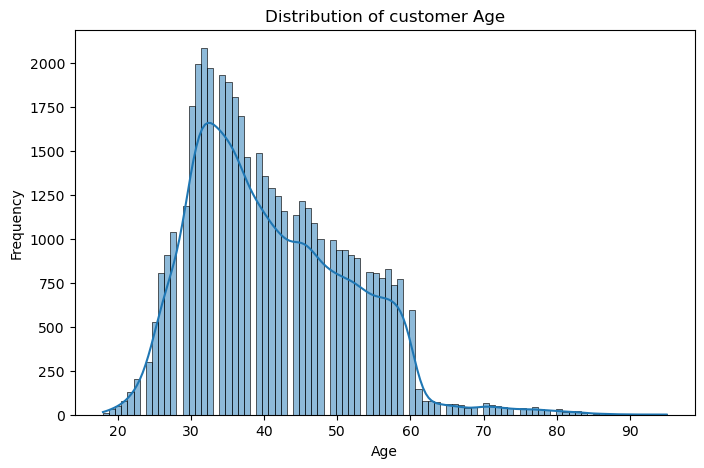

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df,x="age",kde=True)
plt.title("Distribution of customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

### Boxplot of customer age

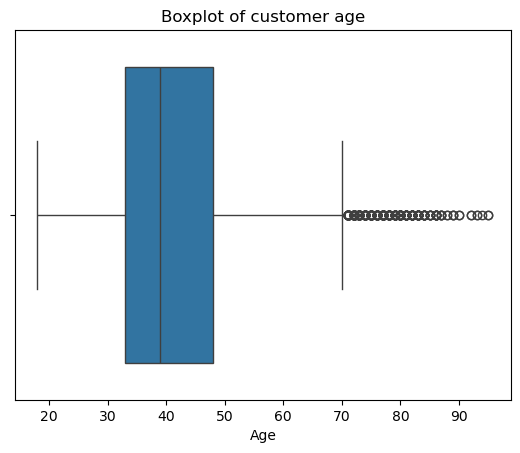

In [16]:
sns.boxplot(data=df,x="age")
plt.title("Boxplot of customer age")
plt.xlabel("Age")
plt.show()

### Countplot of customer jobs

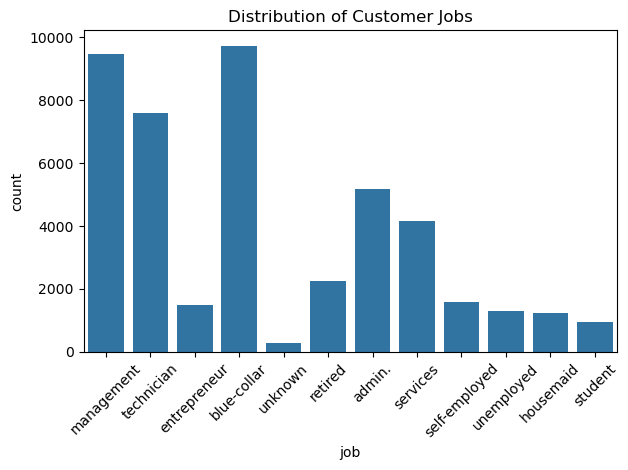

In [17]:
sns.countplot(data=df,x="job")
plt.xticks(rotation=45)
plt.title("Distribution of Customer Jobs")
plt.xlabel("job")
plt.ylabel("count")
plt.tight_layout()
plt.show()

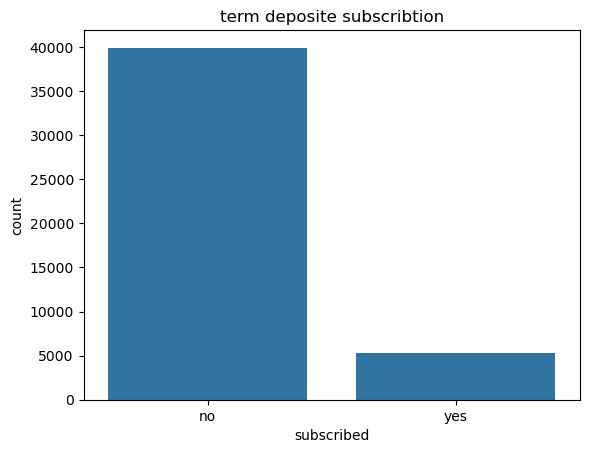

In [18]:
sns.countplot(data=df,x="y")
plt.title("term deposite subscribtion")
plt.xlabel("subscribed")
plt.ylabel("count")
plt.show()

# Bivariate Analysis

### Boxplot of customer age and y

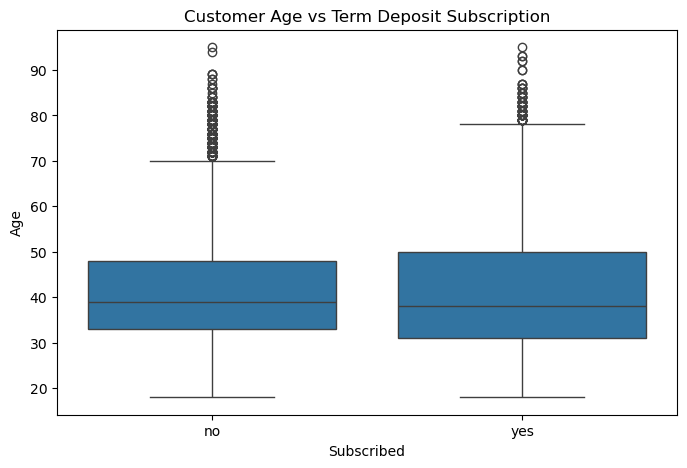

In [19]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x="y", y="age")
plt.title("Customer Age vs Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Age")
plt.show()

### countplot of customer job and y

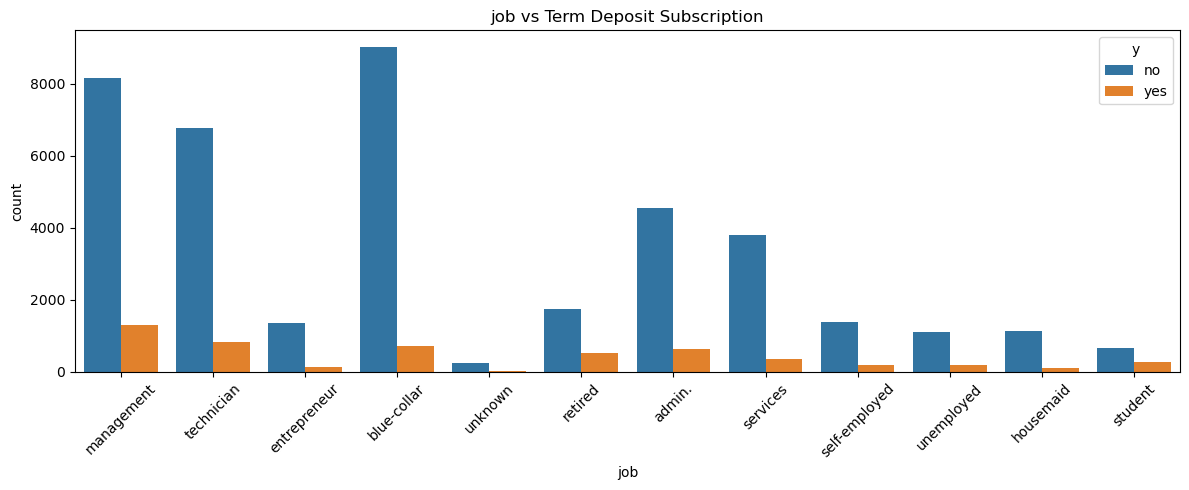

In [20]:
plt.figure(figsize=(12,5))
sns.countplot(data=df,x="job",hue="y")
plt.xticks(rotation=45)
plt.title("job vs Term Deposit Subscription")
plt.xlabel("job")
plt.ylabel("count")
plt.tight_layout()
plt.show()

### countplot Education vs Y

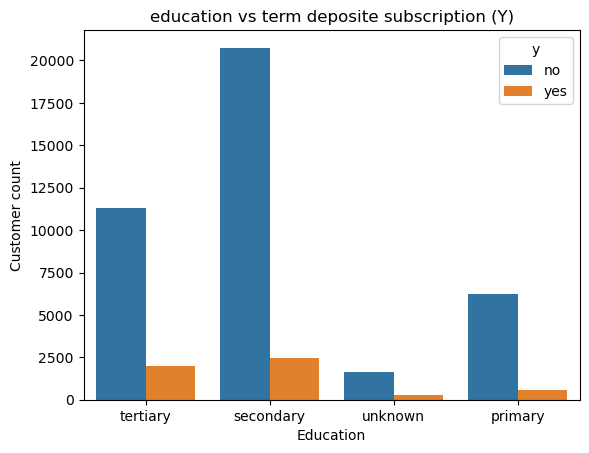

In [26]:
# plt.figure(figsize(8,5))
sns.countplot(data=df,x="education",hue="y")

plt.title("education vs term deposite subscription (Y)")
plt.xlabel("Education")
plt.ylabel("Customer count")
plt.show()

# Multivariate Analysis

### Correlation Heatmap

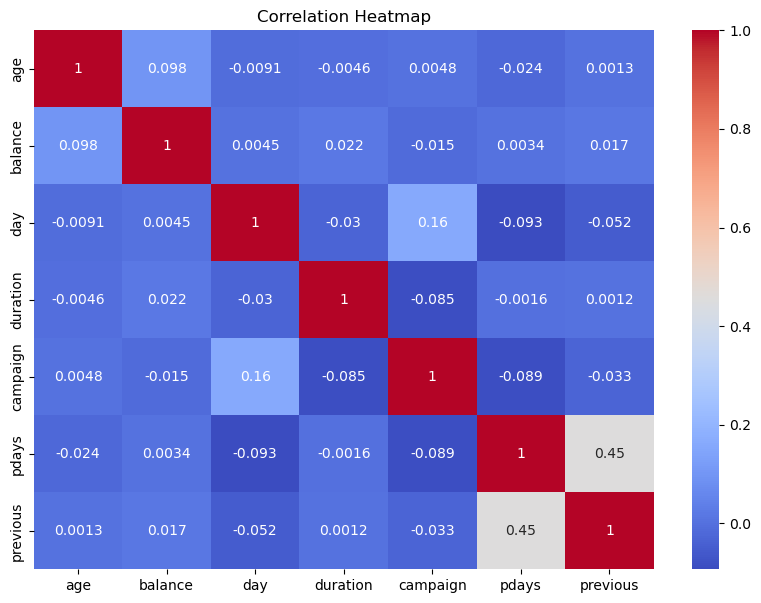

In [21]:
plt.figure(figsize=(10,7)) #---This creates a space for  graph. 10 = graph width./7 = graph height.

sns.heatmap(df.select_dtypes(include="number").corr(),annot=True,cmap="coolwarm")
#This selects only numerical columns

plt.title("Correlation Heatmap")
plt.show()

In [22]:
df["pdays"].corr(df["previous"])

np.float64(0.45481963548050097)

In [23]:
df["campaign"].corr(df["day"])

np.float64(0.1624902163261927)

In [24]:
print(df["y"].value_counts())

print("\nPercentage:")
print(df["y"].value_counts(normalize=True)*100)

y
no     39922
yes     5289
Name: count, dtype: int64

Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


# Overall EDA Summary

## 1. the dataset contains 45,211 customer records and 17 col.
## 2. no missing values or duplicates.
## 3. most customers are between 30 and 40 year old.
## 4. blue-collar and management are among the largest job categories.
## 5. the target variable have weak correlation , except pday and previous , which have a moderate positive correlation of 0.45